

Seed: 3352613

/tmp/ipykernel_1097/2249862255.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=items_rated, x='rating', palette='viridis')


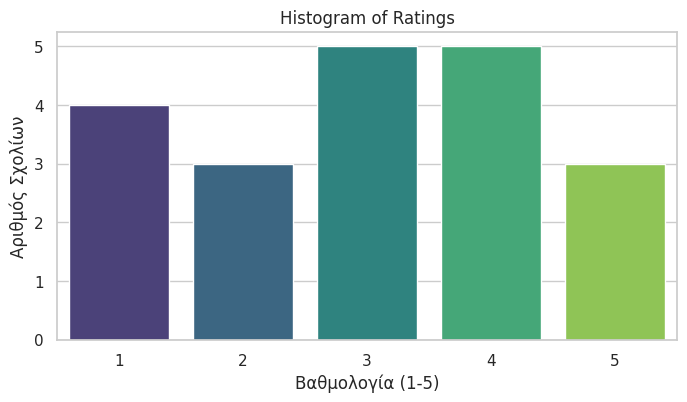

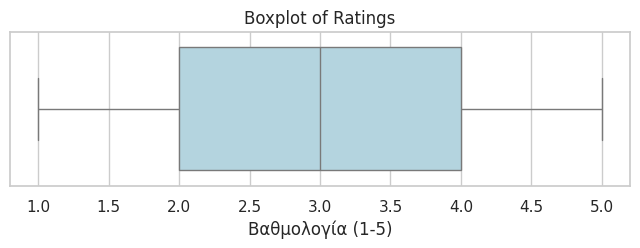

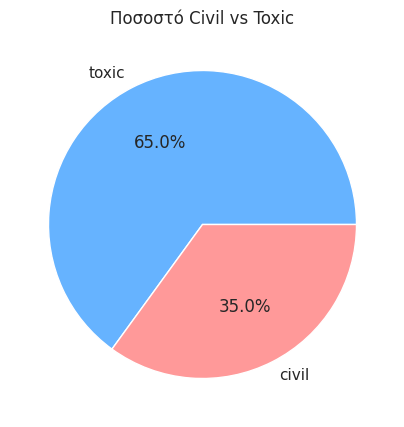

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Φόρτωση των αρχείων
items = pd.read_csv('items.csv')
items_rated = pd.read_csv('items_rated.csv')

# Ορισμός στυλ γραφημάτων
sns.set_theme(style="whitegrid")

#  Ιστόγραμμα
plt.figure(figsize=(8, 4))
sns.countplot(data=items_rated, x='rating', palette='viridis')
plt.title("Histogram of Ratings")
plt.xlabel("Βαθμολογία (1-5)")
plt.ylabel("Αριθμός Σχολίων")
plt.show()

# Boxplot
plt.figure(figsize=(8, 2))
sns.boxplot(data=items_rated, x='rating', color='lightblue')
plt.title("Boxplot of Ratings")
plt.xlabel("Βαθμολογία (1-5)")
plt.show()

# Πόσα Civil vs Toxic
plt.figure(figsize=(5, 5))
items_rated['label'].value_counts().plot.pie(autopct='%1.1f%%', colors=['#66b3ff','#ff9999'])
plt.title("Ποσοστό Civil vs Toxic")
plt.ylabel("")
plt.show()

The graphs show that I used the full 1-5 scale, but my ratings have a strong concentration at 3 and 4. This indicates that my annotations lean towards 'toxic', as I found the majority of the items to be at least borderline disrespectful or hostile.

In [ ]:
from IPython.display import display
import pandas as pd

# Ρυθμίσεις για να εμφανιστούν όλες οι γραμμές και ολόκληρο το κείμενο των σχολίων
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

print("Πίνακας: items.csv")
display(items)

print("\n Πίνακας: items_rated.csv (Με τις βαθμολογίες και το evidence)")
display(items_rated)

Πίνακας: items.csv


,id,text,rating,label,evidence
0,1,"And you were right, Layla. The party showed the proof in record time. Still looks kinda bad for the CPC, but I hereby eat my words.",NaN,NaN,NaN
1,2,James Mason 771: But reading ADN online especially the comments section is the perfect serum for counter-acting the TV induced stupidity.,NaN,NaN,NaN
2,3,"Interesting question, which implies you care about piping plovers, born or unborn. Hardly matters to care about the unborn when one's heart is closed to so many after birth, no?.",NaN,NaN,NaN
3,4,"It's so stupid that some media is saying that as long as Trump doesn't talk about how long or short he hangs, he's won the debate. That may be Republicans' belief, but I doubt seriously that's the way most American voters believe. Go Hillary, and p**** whip him.",NaN,NaN,NaN
4,5,"Out of sight out of mind. All you lazy, entitled people should spend a day in the shoes of a kid living in a garbage dump on one of the island countries. Add a huge bottle deposit so we can guarantee these disgusting products at least end up in the recycling bin.",NaN,NaN,NaN
5,6,"If I were an NFL GM, I would NEVER pick a QB in ANY round that hadn't played in a pro-style system in college. I also think that any college team that doesn't run a pro-style offense is doing a disservice to their players. This is more proof that the NFL needs a minor league system instead of relying on the NCAA.",NaN,NaN,NaN
6,7,*ding ding ding* we have a winner. The lunatic Maxine Waters actually said today that she opposed Trump firing Comey but would've supported Hillary doing it had she won....lol,NaN,NaN,NaN
7,8,Brain-dead bigots like Jefferson Beauregard Sessions see pot laws as a way to feed the for-profit prisons and a way to further the intrusion of the corrupt police state into private lives. It's no surprise Jeffy also loves civil forfeiture.,NaN,NaN,NaN
8,9,It williams be interesting if this starts a full audit into all their expense claims by an independent auditor! I suspect there are quite a few pigs at the trough!,NaN,NaN,NaN
9,10,"Same way Trump did. The ignorant, the gullible and the naive can and do vote.",NaN,NaN,NaN



 Πίνακας: items_rated.csv (Με τις βαθμολογίες και το evidence)


,id,text,rating,label,evidence
0,1,"And you were right, Layla. The party showed the proof in record time. Still looks kinda bad for the CPC, but I hereby eat my words.",2,civil,not needed
1,2,James Mason 771: But reading ADN online especially the comments section is the perfect serum for counter-acting the TV induced stupidity.,3,toxic,stupidity || perfect serum
2,3,"Interesting question, which implies you care about piping plovers, born or unborn. Hardly matters to care about the unborn when one's heart is closed to so many after birth, no?.",3,toxic,Hardly matters to care
3,4,"It's so stupid that some media is saying that as long as Trump doesn't talk about how long or short he hangs, he's won the debate. That may be Republicans' belief, but I doubt seriously that's the way most American voters believe. Go Hillary, and p**** whip him.",4,toxic,"p**** whip him || so stupid || That may be Republicans' belief, but"
4,5,"Out of sight out of mind. All you lazy, entitled people should spend a day in the shoes of a kid living in a garbage dump on one of the island countries. Add a huge bottle deposit so we can guarantee these disgusting products at least end up in the recycling bin.",4,toxic,"All you lazy, entitled people"
5,6,"If I were an NFL GM, I would NEVER pick a QB in ANY round that hadn't played in a pro-style system in college. I also think that any college team that doesn't run a pro-style offense is doing a disservice to their players. This is more proof that the NFL needs a minor league system instead of relying on the NCAA.",1,civil,not needed
6,7,*ding ding ding* we have a winner. The lunatic Maxine Waters actually said today that she opposed Trump firing Comey but would've supported Hillary doing it had she won....lol,4,toxic,The lunatic Maxine Waters || *ding ding ding* we have a winner || ....lol
7,8,Brain-dead bigots like Jefferson Beauregard Sessions see pot laws as a way to feed the for-profit prisons and a way to further the intrusion of the corrupt police state into private lives. It's no surprise Jeffy also loves civil forfeiture.,4,toxic,Brain-dead || Jeffy || bigots
8,9,It williams be interesting if this starts a full audit into all their expense claims by an independent auditor! I suspect there are quite a few pigs at the trough!,3,toxic,there are quite a few pigs at the trough!
9,10,"Same way Trump did. The ignorant, the gullible and the naive can and do vote.",3,toxic,"The ignorant, the gullible and the naive"


Part C: Generate Conversations

In [ ]:
from syndisco import TransformersModel

model = TransformersModel(
    model_path="unsloth/Qwen2.5-3B-Instruct-bnb-4bit",
    name="base_model",
    max_out_tokens=120
)
print("Το μοντέλο φορτώθηκε επιτυχώς")

config.json:   0%|          | 0.00/1.34k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.05GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

Το μοντέλο φορτώθηκε επιτυχώς


In [ ]:
import syndisco
import pandas as pd

# Διαβάζουμε ξανά το αρχείο επειδή η μνήμη καθάρισε
items = pd.read_csv('items.csv')

# Ορίζουμε μια μικρή ομάδα τυχαίων χαρακτήρων
personas_c = [
    {"username": "Alex", "age": 30, "politics": "center", "personality_characteristics": ["analytical", "calm"]},
    {"username": "Jordan", "age": 45, "politics": "left", "personality_characteristics": ["passionate", "opinionated"]},
    {"username": "Taylor", "age": 22, "politics": "right", "personality_characteristics": ["skeptical", "direct"]}
]

# Κοινές οδηγίες για το πώς να συμπεριφέρονται ως χρήστες
INSTRUCTIONS = "Act like a human would in an online comments section. Keep your response short (1-2 sentences)."

# Λίστα για να σώσουμε τα logs
all_conversations = []

print("Ξεκινάει η δημιουργία 20 συζητήσεων\n")

#  Λούπα για κάθε ένα από τα 20 σχόλια
for index, row in items.iterrows():
    item_text = row['text']
    item_id = row['id']

    # Δίνουμε το αρχικό σχόλιο ως Context στους χαρακτήρες για να ξέρουν για τι μιλάνε
    CONTEXT = f"You are taking part in an online conversation. The starting comment is: '{item_text}'"

    # Δημιουργία των Actors
    actors = [
        syndisco.Actor(
            model=model, # Το μοντέλο Qwen που φορτώσαμε προηγουμένως
            persona=p,
            context=CONTEXT,
            instructions=INSTRUCTIONS,
            name=p["username"]
        )
        for p in personas_c
    ]

    # Ρύθμιση της σειράς ομιλίας
    turn_manager = syndisco.QueueTurnManager(actors)

    # Στήσιμο της συζήτησης
    conv = syndisco.Discussion(
        next_turn_manager=turn_manager,
        users=actors,
        conv_len=3, # 3 απαντήσεις ανά συζήτηση, για να είναι μέτριο το μέγεθος όπως ζητάει η εκφώνηση
        seed_opinions=[item_text], # Εδώ μπαίνει το δικό μου σχόλιο για να ξεκινήσει η κουβέντα
        seed_opinion_usernames=["Original_Poster"]
    )

    # Εκτέλεση συζήτησης
    conv.begin()

    # Λήψη των αποτελεσμάτων
    logs = conv.get_logs()
    all_conversations.append(logs)

    # Εκτύπωση για να εμφανιστούν ευανάγνωστα στο Notebook
    print(f"Συζήτηση για το Item {item_id}")
    for entry in logs:
        print(f"[{entry['name']}]: {entry['text']}")
    print("\n" + "-"*50 + "\n")

print("Η παραγωγή των 20 συζητήσεων ολοκληρώθηκε")

Ξεκινάει η δημιουργία 20 συζητήσεων



  0%|          | 0/3 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=120) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=120) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Comment by user Alex: "
Thanks, Layla. It's always good to see swift action when it matters." 



[transformers] Both `max_new_tokens` (=120) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

  0%|          | 0/3 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=120) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=120) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Comment by user Alex: "
I agree with the original poster. Conservative values can indeed be harmful when they lead to discrimination and disregard for human rights." 



[transformers] Both `max_new_tokens` (=120) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Comment by user Jordan: "
I completely agree with the original poster. Conservative values often lead to systemic injustices and ignore the rights of marginalized groups." 

Comment by user Taylor: "
I respectfully disagree with the original poster. While I acknowledge there are issues with conservative values, I believe it's too simplistic to paint them all with one brush. There are also many conservatives who advocate for equality and justice." 

Συζήτηση για το Item 20
[Original_Poster]: I think he means "conservative values" like discriminating against people based on national origin, race, religion and sexual orientation and allowing the wholesale slaughter of citizens in exchange for donations from the gun lobby.
[Alex]: I agree with the original poster. Conservative values can indeed be harmful when they lead to discrimination and disregard for human rights.
[Jordan]: I completely agree with the original poster. Conservative values often lead to systemic injustices and ignore th

Part C Explanations:

I made 1 conversation for each item. I used 3 participants and 3 comments in total. I told them to write short answers (1-2 sentences). This keeps the text small, so the model can read it easily in the next steps. I chose the unsloth/Qwen2.5-3B-Instruct-bnb-4bit model because it is fast, works perfectly on the Colab GPU, and does a good job.

In [ ]:
# Το προσαρμοσμένο πλέγμα ταυτοτήτων για τους αξιολογητές
personas_grid = [
    {}, # baseline (χωρίς persona)
    {"gender": "woman", "politics": "left", "education": "degree"},
    {"gender": "woman", "politics": "right", "education": "high school"},
    {"gender": "man", "politics": "left", "education": "high school"},
    {"gender": "man", "politics": "right", "education": "degree"},
    {"gender": "non-binary", "politics": "center", "education": "degree"}
]

print("Το πλέγμα ταυτοτήτων δημιουργήθηκε")

Το πλέγμα ταυτοτήτων δημιουργήθηκε


Part D & E Explanations:

I changed the starting grid. I used "education" instead of "age". I also added a "non-binary" person with "center" politics. I kept the grid small (5 personas + 1 baseline) so the code runs fast on the Colab GPU.

In [ ]:
import pandas as pd
import syndisco
import re
from IPython.display import display

# Οι οδηγίες βαθμολόγησης (ίδιες για όλους)
INSTRUCTIONS = (
    "Rate the following comment from 1 (fully civil) to 5 (very toxic). "
    "If you rate it 3, 4, or 5, you MUST also quote the exact toxic words from the comment. "
    "Format your answer EXACTLY like this: 'Rating: X | Evidence: Y'. "
    "If the rating is 1 or 2, just write 'Rating: X | Evidence: not needed'."
)

results_D = [] # Αποτελέσματα με Context (Συζήτηση)
results_E = [] # Αποτελέσματα χωρίς Context

print("Ξεκινάει η βαθμολόγηση\n")

for p_idx, persona in enumerate(personas_grid):
    annotator_name = f"Persona_{p_idx}" if persona else "Baseline"
    print(f"Αξιολογεί: {annotator_name}...")

    for idx, row in items.iterrows():
        item_text = row['text']
        item_id = row['id']

        #  Φτιάχνουμε ένα Log που περιέχει μόνο το προς αξιολόγηση σχόλιο
        item_log = syndisco.Logs()
        item_log.append("Original_Poster", item_text)

        # Ανάκτηση της συζήτησης από το Part C για να μπει ως Context στο Part D
        conv_logs = all_conversations[idx]
        conv_text = "\n".join([f"{entry['name']}: {entry['text']}" for entry in conv_logs])

        #  PART D (WITH CONTEXT)
        actor_D = syndisco.Actor(
            model=model,
            persona=persona,
            context=f"Read this conversation first:\n{conv_text}",
            instructions=INSTRUCTIONS,
            is_annotator=True
        )

        ann_conv_D = syndisco.Annotation(annotator=actor_D, discussion_logs=item_log)
        ann_conv_D.begin()
        log_D = ann_conv_D.get_logs()[0]

        #  PART E (NO CONTEXT)
        actor_E = syndisco.Actor(
            model=model,
            persona=persona,
            context="", # Κενό context για το Part E
            instructions=INSTRUCTIONS,
            is_annotator=True
        )

        ann_conv_E = syndisco.Annotation(annotator=actor_E, discussion_logs=item_log)
        ann_conv_E.begin()
        log_E = ann_conv_E.get_logs()[0]

        #  Συνάρτηση εξαγωγής βαθμολογίας και evidence
        def parse_answer(ans_text):
            match = re.search(r'([1-5])', ans_text)
            if match:
                rating = int(match.group(1))
                label = "civil" if rating <= 2 else "toxic"
                evidence = "not needed"
                if rating >= 3:
                    if "Evidence:" in ans_text:
                        evidence = ans_text.split("Evidence:")[-1].strip()
                    else:
                        evidence = ans_text # Αν απέτυχε η μορφοποίηση, σώσε όλο το κείμενο
            else:
                rating = None
                label = "invalid"
                evidence = "invalid"
            return rating, label, evidence

        r_D, l_D, e_D = parse_answer(log_D['text'])
        r_E, l_E, e_E = parse_answer(log_E['text'])

        results_D.append({'id': item_id, 'text': item_text, 'rating': r_D, 'label': l_D, 'evidence': e_D, 'annotator': annotator_name, 'prompt': log_D.get('prompt', '')})
        results_E.append({'id': item_id, 'text': item_text, 'rating': r_E, 'label': l_E, 'evidence': e_E, 'annotator': annotator_name, 'prompt': log_E.get('prompt', '')})

df_D = pd.DataFrame(results_D)
df_E = pd.DataFrame(results_E)

# Εκτύπωση των τελικών DataFrames για την εργασία
pd.set_option('display.max_rows', None)
print("\nPart D: Με Context (Διάβασαν τη συζήτηση)")
display(df_D)
print("\nPart E: Χωρίς Context (Είδαν μόνο το σχόλιο)")
display(df_E)

Ξεκινάει η βαθμολόγηση

Αξιολογεί: Baseline...


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=120) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Comment by user Original_Poster: " And you were right, Layla. The
party showed the proof in record time. Still looks kinda bad for the
CPC, but I hereby eat my words."
Rating: 2 | Evidence: not needed


  0%|          | 0/1 [00:00<?, ?it/s]

...

[transformers] Both `max_new_tokens` (=120) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Comment by user Original_Poster: " I think he means "conservative
values" like discriminating against people based on national origin,
race, religion and sexual orientation and allowing the wholesale
slaughter of citizens in exchange for donations from the gun lobby."
Rating: 1 | Evidence: not needed

Part D: Με Context (Διάβασαν τη συζήτηση)


,id,text,rating,label,evidence,annotator,prompt
0,1,"And you were right, Layla. The party showed th...",2,civil,not needed,Baseline,"{""context"": ""Read this conversation first:\nOr..."
1,2,James Mason 771: But reading ADN online especi...,2,civil,not needed,Baseline,"{""context"": ""Read this conversation first:\nOr..."
2,3,"Interesting question, which implies you care a...",2,civil,not needed,Baseline,"{""context"": ""Read this conversation first:\nOr..."
3,4,It's so stupid that some media is saying that ...,2,civil,not needed,Baseline,"{""context"": ""Read this conversation first:\nOr..."
4,5,"Out of sight out of mind. All you lazy, entitl...",2,civil,not needed,Baseline,"{""context"": ""Read this conversation first:\nOr..."
5,6,"If I were an NFL GM, I would NEVER pick a QB i...",2,civil,not needed,Baseline,"{""context"": ""Read this conversation first:\nOr..."
6,7,*ding ding ding* we have a winner. The lunatic...,3,toxic,*ding ding ding* we have a winner. The lunatic...,Baseline,"{""context"": ""Read this conversation first:\nOr..."
7,8,Brain-dead bigots like Jefferson Beauregard Se...,2,civil,not needed,Baseline,"{""context"": ""Read this conversation first:\nOr..."
8,9,It williams be interesting if this starts a fu...,2,civil,not needed,Baseline,"{""context"": ""Read this conversation first:\nOr..."
9,10,"Same way Trump did. The ignorant, the gullible...",2,civil,not needed,Baseline,"{""context"": ""Read this conversation first:\nOr..."



Part E: Χωρίς Context (Είδαν μόνο το σχόλιο)


,id,text,rating,label,evidence,annotator,prompt
0,1,"And you were right, Layla. The party showed th...",1,civil,not needed,Baseline,"{""context"": """", ""instructions"": ""Rate the foll..."
1,2,James Mason 771: But reading ADN online especi...,1,civil,not needed,Baseline,"{""context"": """", ""instructions"": ""Rate the foll..."
2,3,"Interesting question, which implies you care a...",2,civil,not needed,Baseline,"{""context"": """", ""instructions"": ""Rate the foll..."
3,4,It's so stupid that some media is saying that ...,3,toxic,"""p****""",Baseline,"{""context"": """", ""instructions"": ""Rate the foll..."
4,5,"Out of sight out of mind. All you lazy, entitl...",2,civil,not needed,Baseline,"{""context"": """", ""instructions"": ""Rate the foll..."
5,6,"If I were an NFL GM, I would NEVER pick a QB i...",1,civil,not needed,Baseline,"{""context"": """", ""instructions"": ""Rate the foll..."
6,7,*ding ding ding* we have a winner. The lunatic...,1,civil,not needed,Baseline,"{""context"": """", ""instructions"": ""Rate the foll..."
7,8,Brain-dead bigots like Jefferson Beauregard Se...,1,civil,not needed,Baseline,"{""context"": """", ""instructions"": ""Rate the foll..."
8,9,It williams be interesting if this starts a fu...,1,civil,not needed,Baseline,"{""context"": """", ""instructions"": ""Rate the foll..."
9,10,"Same way Trump did. The ignorant, the gullible...",1,civil,not needed,Baseline,"{""context"": """", ""instructions"": ""Rate the foll..."


Σύγκριση των Μοντέλων με ΕΜΕΝΑ (και με τον εαυτό τους)


,Annotator,Cat. Agree (No Context),Num. Agree (No Context),Cat. Agree (With Context),Num. Agree (With Context),Self Agree (Context Impact)
0,Baseline,0.55,0.25,0.55,0.30,0.90
1,Persona_1,0.55,0.30,0.50,0.25,0.85
2,Persona_2,0.50,0.25,0.50,0.25,0.80
3,Persona_3,0.50,0.25,0.50,0.25,0.90
4,Persona_4,0.50,0.25,0.50,0.25,0.80
5,Persona_5,0.55,0.30,0.50,0.25,0.75



 Συμφωνία Persona vs Persona (Heatmaps)


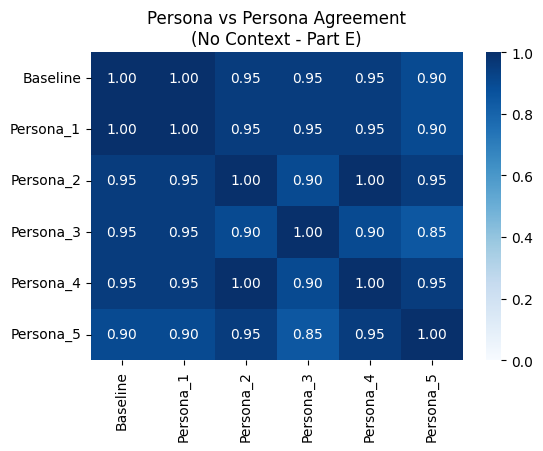

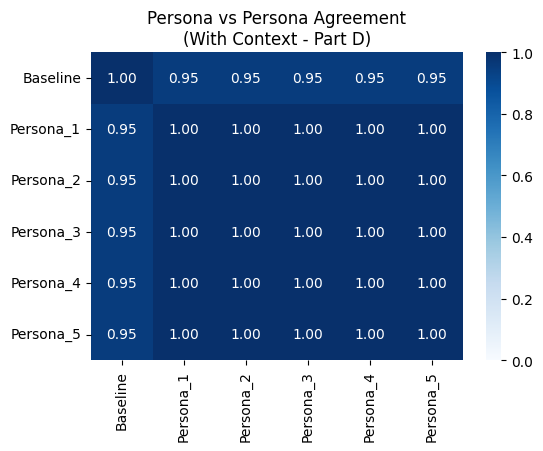

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#  Φορτώνω ξανά  τις δικές μου βαθμολογίες
my_ratings = pd.read_csv('items_rated.csv')

# Συνάρτηση για υπολογισμό Simple Agreement (ποσοστό ταύτισης)
def calc_agreement(df1, df2, col_name):
    merged = pd.merge(df1[['id', col_name]], df2[['id', col_name]], on='id')
    valid_mask = merged[col_name + '_x'].notna() & merged[col_name + '_y'].notna()
    agreement = (merged.loc[valid_mask, col_name + '_x'] == merged.loc[valid_mask, col_name + '_y']).mean()
    return agreement if pd.notna(agreement) else 0

print("Σύγκριση των Μοντέλων με ΕΜΕΝΑ (και με τον εαυτό τους)")
annotators = df_E['annotator'].unique()
results = []

for ann in annotators:
    ann_E = df_E[df_E['annotator'] == ann]
    ann_D = df_D[df_D['annotator'] == ann]

    # Με εμένα χωρίς context (E)
    cat_E = calc_agreement(my_ratings, ann_E, 'label')
    num_E = calc_agreement(my_ratings, ann_E, 'rating')

    #  Με εμένα με context (D)
    cat_D = calc_agreement(my_ratings, ann_D, 'label')
    num_D = calc_agreement(my_ratings, ann_D, 'rating')

    #  Ο annotator με τον εαυτό του (E vs D) - Πόσο τον επηρέασε το context;
    cat_self = calc_agreement(ann_E, ann_D, 'label')

    results.append({
        'Annotator': ann,
        'Cat. Agree (No Context)': cat_E,
        'Num. Agree (No Context)': num_E,
        'Cat. Agree (With Context)': cat_D,
        'Num. Agree (With Context)': num_D,
        'Self Agree (Context Impact)': cat_self
    })

df_results = pd.DataFrame(results)
display(df_results.round(2))

print("\n Συμφωνία Persona vs Persona (Heatmaps)")
def plot_heatmap(df, condition_name):
    matrix = pd.DataFrame(index=annotators, columns=annotators)
    for a1 in annotators:
        for a2 in annotators:
            df1 = df[df['annotator'] == a1]
            df2 = df[df['annotator'] == a2]
            matrix.loc[a1, a2] = calc_agreement(df1, df2, 'label')

    matrix = matrix.astype(float)
    plt.figure(figsize=(6, 4))
    sns.heatmap(matrix, annot=True, cmap='Blues', vmin=0, vmax=1, fmt='.2f')
    plt.title(f"Persona vs Persona Agreement\n({condition_name})")
    plt.show()

plot_heatmap(df_E, "No Context - Part E")
plot_heatmap(df_D, "With Context - Part D")

**Part G: Results and Story**

First, I checked how close the models are to my own ratings. Without the conversation context, Persona 1 and Persona 5 were the closest to me. They agreed with me on 55% of the items. The baseline model also had a 0.55 score.

When the models read the conversation first (with context), they actually moved further away from my ratings. All personas dropped to a 0.50 agreement score. Only the baseline stayed at 0.55.

Next, I looked at how much the context changed each model's answers. Persona 5 changed its labels the most between the two conditions (it agreed with its older self 75% of the time, meaning it changed 25% of its answers).

Then, I compared the personas against each other using heatmaps. Without context, they had some small disagreements. But after reading the conversation, Personas 1 to 5 agreed with each other perfectly (a 1.00 score). Because they agreed perfectly with context, no specific dimension (like education, gender, or politics) mattered more than the others. The conversation made them all act exactly the same.

Finally, even though Persona 1 and 5 were the "closest" to me without context, this does not mean I share their identity. This study has big limitations. We only used 20 items, which is a very small sample. We used a small model (3B), and the generated conversation is just one random example, which adds its own bias. Also, the personas are just simple text descriptions, not real people.

